# 03 · Model 1 — Linear Regression

**Idea:** predict RUL as a **weighted sum** of the features (multiple linear regression):

`RUL ≈ b + w1·x1 + w2·x2 + … + w71·x71`

The weights are found with **Ordinary Least Squares (OLS)** — they minimise the sum of squared errors (RSS).

We put a `StandardScaler` first (standardisation: mean 0, std 1) so all weights are on the same scale and can be compared.
This is our **simplest model** and our reference for the others.


> 💡 Cells marked with **⋯** are hidden because they only contain plotting or helper code. Click them to expand.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from utils import evaluate, plot_validation, plot_test, stage_table, savefig, RUL_CAP

NAME = "Linear Regression"

## 1. Load the features (made in notebook 02)

In [2]:
# Feature tables made in notebook 02
train = pd.read_csv("../data/processed/train_features.csv")   # 100 training engines, every cycle
test = pd.read_csv("../data/processed/test_features.csv")     # 100 test engines, last cycle only
FEATURES = open("../data/processed/feature_list.txt").read().split()   # the 71 feature names

# Notebook 02 put each training engine in "train" (80 engines) or "val" (20 engines)
tr = train[train["split"] == "train"]
val = train[train["split"] == "val"]

X_train, y_train = tr[FEATURES], tr["RUL"]
X_val, y_val = val[FEATURES], val["RUL"]
groups = tr["unit"]   # engine ID of each row -> cross-validation keeps one engine in one fold
print(f"Training engines: {tr['unit'].nunique()} | Validation engines: {val['unit'].nunique()} | Features: {len(FEATURES)}")

Training engines: 80 | Validation engines: 20 | Features: 71


## 2. Train the model
Plain Linear Regression has **no hyper-parameters**, so there is nothing to tune.
We first check it with **3-fold cross-validation** (`GroupKFold`: all rows of one engine stay in the same fold → no leakage),
then fit it on all 80 training engines.

In [3]:
base_model = Pipeline([("scaler", StandardScaler()),          # standardisation (learned on training data only)
                       ("model", LinearRegression())])        # OLS

# No hyper-parameters to tune -> just check the model with 3-fold cross-validation, then fit it
cv_rmse = -cross_val_score(base_model, X_train, y_train, groups=groups, cv=GroupKFold(n_splits=3),
                           scoring="neg_root_mean_squared_error")
print("Cross-validation RMSE per fold:", cv_rmse.round(2), "→ average:", cv_rmse.mean().round(2))
model = base_model.fit(X_train, y_train)

Cross-validation RMSE per fold: [17.01 17.47 19.96] → average: 18.15


## 3. Results on the validation engines
* **MAE** — average error in cycles
* **RMSE** — √MSE, typical error in cycles (big mistakes count more)
* **R²** — 1 − RSS/TSS: how much of the variation is explained (1 = perfect, 0 = as good as the average)

In [4]:
val_pred = np.clip(model.predict(X_val), 0, RUL_CAP)     # RUL can't be below 0 or above the cap
pd.DataFrame([evaluate(y_val, val_pred)], index=[NAME + " (validation)"])

,RMSE,MAE,R2
Linear Regression (validation),15.29,11.94,0.866


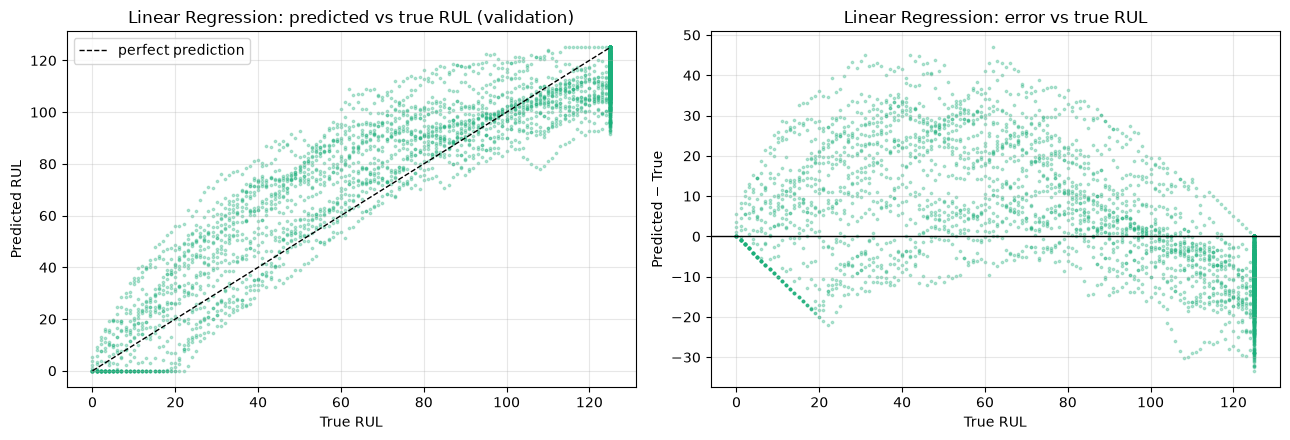

In [5]:
plot_validation(NAME, y_val, val_pred, "03_validation")

**How to read:** left — points on the dashed line are perfect predictions. Right — points above 0 mean the model
predicted **too much** life left (dangerous), below 0 means **too little** (safe but wasteful).

## 4. Which features matter?
For a linear model we look at the **weights (coefficients)**: big weight = big influence. Features were standardised, so the weights can be compared.

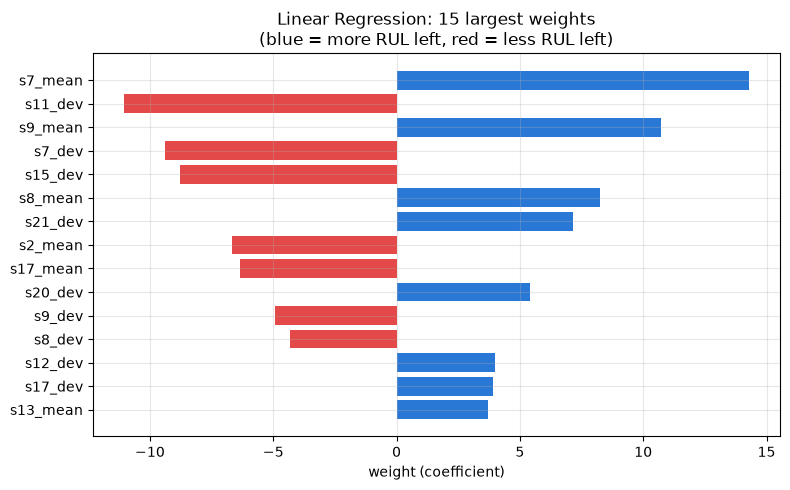

Linear Regression uses 71 of 71 features (the others got weight 0)


In [6]:
coef = pd.Series(model.named_steps["model"].coef_, index=FEATURES)
top = coef[coef.abs().nlargest(15).index]
plt.figure(figsize=(8, 5))
plt.barh(top.index[::-1], top.values[::-1], color=["#2a78d6" if v > 0 else "#e34948" for v in top.values[::-1]])
plt.title(f"{NAME}: 15 largest weights\n(blue = more RUL left, red = less RUL left)"); plt.xlabel("weight (coefficient)")
savefig("03_weights")
print(f"{NAME} uses {(coef.abs() > 1e-6).sum()} of {len(coef)} features (the others got weight 0)")

## 5. Do the engineered features help?
Same model, same settings, but trained with **only the raw sensors + cycle** (15 features instead of 71).

In [7]:
RAW = [f for f in FEATURES if "_" not in f]   # cycle + 14 raw sensors
raw_model = clone(model).fit(X_train[RAW], y_train)   # clone = untrained copy with the same settings
raw_rmse = evaluate(y_val, np.clip(raw_model.predict(val[RAW]), 0, RUL_CAP))["RMSE"]
eng_rmse = evaluate(y_val, val_pred)["RMSE"]

pd.DataFrame({"Validation RMSE": [raw_rmse, eng_rmse]},
             index=["Raw sensors only (15 features)", "With engineered features (71)"])

,Validation RMSE
Raw sensors only (15 features),17.37
With engineered features (71),15.29


## 6. Early vs late life
* **Early:** true RUL > 100 (engine still healthy)
* **Late:** true RUL ≤ 100 (engine is wearing out — the important part for maintenance)

In [8]:
stage_table(val["RUL_raw"], y_val, val_pred)

,Rows,RMSE,MAE
Stage,,,
early (RUL > 100),2050,12.23,9.67
late (RUL ≤ 100),2020,17.86,14.24


## 7. Official NASA test set (100 engines)
* Re-train the model with the same settings on **all 100 training engines**.
* Predict each test engine **once, at its last recorded cycle**, and compare with the true RUL from `RUL_FD001.txt`.
* Nothing is tuned on the test set.

In [9]:
final_model = clone(model).fit(train[FEATURES], train["RUL"])   # same settings, trained on all 100 engines
test_pred = np.clip(final_model.predict(test[FEATURES]), 0, RUL_CAP)
pd.DataFrame([evaluate(test["RUL"], test_pred)], index=[NAME + " (test)"])

,RMSE,MAE,R2
Linear Regression (test),15.85,12.84,0.844


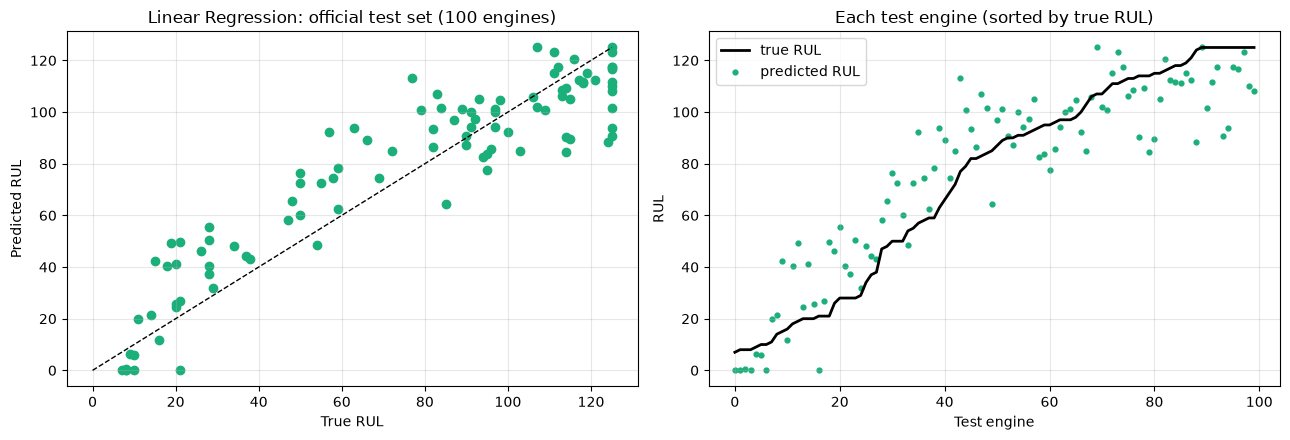

In [10]:
plot_test(NAME, test["RUL"], test_pred, "03_test")

## 8. Save the model and predictions (used by notebook 06 and the web app)

In [11]:
joblib.dump(final_model, "../outputs/models/linear_regression.joblib")

# Save predictions so notebook 06 can compare all models without training them again
val[["unit", "cycle", "RUL_raw", "RUL"]].assign(predicted=val_pred).to_csv(
    "../outputs/results/linear_regression_val_predictions.csv", index=False)
test[["unit", "RUL_raw", "RUL"]].assign(predicted=test_pred).to_csv(
    "../outputs/results/linear_regression_test_predictions.csv", index=False)
pd.DataFrame([{"Model": NAME, "raw_sensors_only_val_RMSE": raw_rmse}]).to_csv(
    "../outputs/results/linear_regression_raw_vs_engineered.csv", index=False)
print("Saved model and predictions")

Saved model and predictions


## ✅ Summary — Linear Regression
* Much better than guessing the average, and **very easy to explain** (one weight per feature).
* But it can only draw a **straight line**: the real pattern is "flat for a long time, then a fast drop", so errors stay big.
* Many features are strongly correlated (**multicollinearity**) → some weights become large with opposite signs
  that cancel out, so single weights are hard to interpret.
* Next: a **Decision Tree**, which can learn non-linear patterns → notebook 04.

**Viva quick answers**
* *What does OLS minimise?* The sum of squared residuals (RSS) between true and predicted RUL.
* *Why scale features?* So the weights are comparable.